In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "clean" / "cleaned_data.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (10000, 42)


,campaign_objective,platform,ad_placement,device_type,operating_system,creative_format,creative_size,ad_copy_length,has_call_to_action,creative_emotion,...,budget_tier,CTR,CPC,conversion_rate,CPA,ROAS,profit,start_year,start_month,start_day
0,Lead Generation,Facebook,Search,Mobile,Android,Text,728x90,Short,False,Curiosity,...,High,0.606,2.23,0.498,448.23,0.32,-606.79,2024,3,6
1,Engagement,Facebook,Feed,Mobile,iOS,Image,320x50,Long,True,Neutral,...,Medium,0.932,2.48,1.071,231.63,1.49,570.04,2024,1,26
2,Conversions,Google Ads,Feed,Tablet,iOS,Video,1920x1080,Short,False,Urgency,...,Low,1.033,3.88,5.357,72.43,6.68,2468.70,2025,5,15
3,Conversions,LinkedIn,Search,Desktop,iOS,Carousel,1920x1080,Short,False,Joy,...,Medium,1.573,8.29,2.439,339.89,0.49,-517.39,2024,7,21
4,Brand Awareness,Facebook,Stories,Mobile,iOS,Image,1920x1080,Short,False,Joy,...,Low,1.409,1.41,0.000,0.00,0.00,-425.82,2025,3,9


In [3]:
df["campaign_success"] = (df["profit"] > 0).astype(int)

print("Campaign success target created!")
print("\nTarget distribution:")
print(df["campaign_success"].value_counts())

print("\nTarget distribution in percentage:")
print(
    (df["campaign_success"].value_counts(normalize=True) * 100)
    .round(2)
)

Campaign success target created!

Target distribution:
campaign_success
1    7831
0    2169
Name: count, dtype: int64

Target distribution in percentage:
campaign_success
1    78.31
0    21.69
Name: proportion, dtype: float64


In [4]:
target = "campaign_success"

leakage_columns = [
    "campaign_success",
    "profit",
    "revenue",
    "ad_spend",
    "ROAS",
    "CTR",
    "CPC",
    "conversion_rate",
    "CPA",
    "clicks",
    "conversions",
]

X = df.drop(columns=leakage_columns, errors="ignore")
y = df[target]

# Remove unique campaign identifier, if present
X = X.drop(columns=["campaign_id"], errors="ignore")

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (10000, 32)
Target shape: (10000,)

Feature columns:
['campaign_objective', 'platform', 'ad_placement', 'device_type', 'operating_system', 'creative_format', 'creative_size', 'ad_copy_length', 'has_call_to_action', 'creative_emotion', 'creative_age_days', 'target_audience_age', 'target_audience_gender', 'audience_interest_category', 'income_bracket', 'purchase_intent_score', 'retargeting_flag', 'quarter', 'day_of_week', 'hour_of_day', 'campaign_day', 'quality_score', 'actual_cpc', 'impressions', 'bounce_rate', 'avg_session_duration_seconds', 'pages_per_session', 'industry_vertical', 'budget_tier', 'start_year', 'start_month', 'start_day']


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (8000, 32)
X_test shape: (2000, 32)
y_train shape: (8000,)
y_test shape: (2000,)


In [6]:
categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

print("Categorical features:", len(categorical_features))
print(categorical_features)

print("\nNumerical features:", len(numerical_features))
print(numerical_features)

Categorical features: 19
['campaign_objective', 'platform', 'ad_placement', 'device_type', 'operating_system', 'creative_format', 'creative_size', 'ad_copy_length', 'has_call_to_action', 'creative_emotion', 'target_audience_age', 'target_audience_gender', 'audience_interest_category', 'income_bracket', 'purchase_intent_score', 'retargeting_flag', 'day_of_week', 'industry_vertical', 'budget_tier']

Numerical features: 13
['creative_age_days', 'quarter', 'hour_of_day', 'campaign_day', 'quality_score', 'actual_cpc', 'impressions', 'bounce_rate', 'avg_session_duration_seconds', 'pages_per_session', 'start_year', 'start_month', 'start_day']


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed X_train shape:", X_train_processed.shape)
print("Processed X_test shape:", X_test_processed.shape)

Processed X_train shape: (8000, 101)
Processed X_test shape: (2000, 101)


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced",
        random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1,
        random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train_processed, y_train)

    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("F1 Score", ascending=False)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,Gradient Boosting,0.8965,0.8953,0.9828,0.9370,0.9463
2,Random Forest,0.8430,0.8402,0.9872,0.9078,0.9126
0,Logistic Regression,0.8385,0.9494,0.8384,0.8905,0.9199
1,Decision Tree,0.7960,0.8637,0.8780,0.8708,0.6890


Classification Report:

              precision    recall  f1-score   support

Unsuccessful       0.90      0.59      0.71       434
  Successful       0.90      0.98      0.94      1566

    accuracy                           0.90      2000
   macro avg       0.90      0.78      0.82      2000
weighted avg       0.90      0.90      0.89      2000



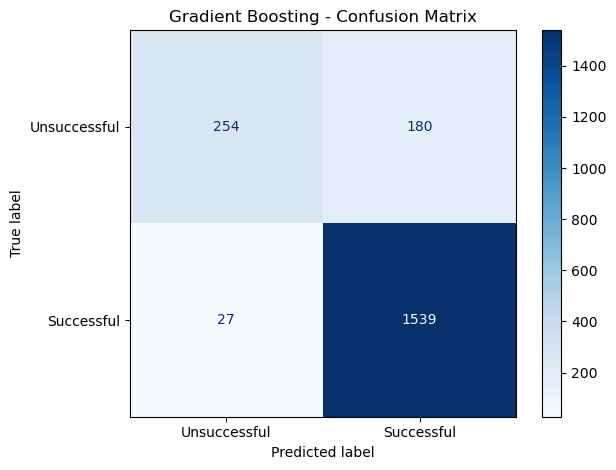

In [9]:
best_model = models["Gradient Boosting"]

y_pred = best_model.predict(X_test_processed)
y_prob = best_model.predict_proba(X_test_processed)[:, 1]

print("Classification Report:\n")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Unsuccessful", "Successful"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Unsuccessful", "Successful"],
    cmap="Blues"
)

plt.title("Gradient Boosting - Confusion Matrix")
plt.tight_layout()
plt.show()

In [10]:
import joblib
from pathlib import Path

models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(best_model, models_dir / "success_model.pkl")
joblib.dump(preprocessor, models_dir / "success_preprocessor.pkl")

print("Success model saved!")
print("Preprocessor saved!")
print("Model path:", models_dir / "success_model.pkl")
print("Preprocessor path:", models_dir / "success_preprocessor.pkl")

Success model saved!
Preprocessor saved!
Model path: c:\Users\ASUS\Desktop\AI Marketing Campaign\models\success_model.pkl
Preprocessor path: c:\Users\ASUS\Desktop\AI Marketing Campaign\models\success_preprocessor.pkl


In [11]:
sample_campaign = X_test.iloc[[0]]

sample_processed = preprocessor.transform(sample_campaign)

prediction = best_model.predict(sample_processed)[0]
probability = best_model.predict_proba(sample_processed)[0][1] * 100

print("Predicted Result:", "Successful" if prediction == 1 else "Unsuccessful")
print(f"Success Probability: {probability:.2f}%")

Predicted Result: Successful
Success Probability: 97.36%


In [12]:
from sklearn.metrics import precision_recall_curve

y_prob = best_model.predict_proba(X_test_processed)[:, 1]

thresholds_to_test = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
threshold_results = []

for threshold in thresholds_to_test:
    y_pred_tuned = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred_tuned),
        "Precision": precision_score(y_test, y_pred_tuned, zero_division=0),
        "Recall": recall_score(y_test, y_pred_tuned, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred_tuned, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.3,0.8445,0.8357,0.9974,0.9095
1,0.4,0.8680,0.8617,0.9904,0.9216
2,0.5,0.8965,0.8953,0.9828,0.9370
3,0.6,0.8925,0.9183,0.9470,0.9324
4,0.7,0.8780,0.9478,0.8934,0.9198
5,0.8,0.8370,0.9733,0.8142,0.8866


In [13]:
for threshold in [0.5, 0.6, 0.7]:
    y_pred_tuned = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print(classification_report(
        y_test,
        y_pred_tuned,
        target_names=["Unsuccessful", "Successful"],
        zero_division=0
    ))


Threshold: 0.5
              precision    recall  f1-score   support

Unsuccessful       0.90      0.59      0.71       434
  Successful       0.90      0.98      0.94      1566

    accuracy                           0.90      2000
   macro avg       0.90      0.78      0.82      2000
weighted avg       0.90      0.90      0.89      2000


Threshold: 0.6
              precision    recall  f1-score   support

Unsuccessful       0.78      0.70      0.74       434
  Successful       0.92      0.95      0.93      1566

    accuracy                           0.89      2000
   macro avg       0.85      0.82      0.83      2000
weighted avg       0.89      0.89      0.89      2000


Threshold: 0.7
              precision    recall  f1-score   support

Unsuccessful       0.68      0.82      0.75       434
  Successful       0.95      0.89      0.92      1566

    accuracy                           0.88      2000
   macro avg       0.81      0.86      0.83      2000
weighted avg       0.89   

In [14]:
import joblib

best_threshold = 0.6

model_info = {
    "model_name": "Gradient Boosting Classifier",
    "success_definition": "profit > 0",
    "classification_threshold": best_threshold,
    "features": X.columns.tolist(),
    "accuracy_at_0.5": accuracy_score(
        y_test, (y_prob >= 0.5).astype(int)
    ),
    "accuracy_at_0.6": accuracy_score(
        y_test, (y_prob >= best_threshold).astype(int)
    ),
}

joblib.dump(model_info, models_dir / "success_model_info.pkl")

print("Final threshold:", best_threshold)
print("Model information saved successfully!")

Final threshold: 0.6
Model information saved successfully!
